In [1]:
import sys
print(sys.executable)

/opt/anaconda3/envs/poemas-ia/bin/python


In [2]:
import sys
import pandas as pd
import numpy as np
import sklearn
from datasets import load_dataset

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Entorno listo")

Python: /opt/anaconda3/envs/poemas-ia/bin/python
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
Entorno listo


/opt/anaconda3/envs/poemas-ia/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("google-research-datasets/poem_sentiment")

print(dataset)

etiquetas = dataset["train"].features["label"].names
print("\nEtiquetas originales:")
for indice, nombre in enumerate(etiquetas):
    print(f"{indice}: {nombre}")

DatasetDict({
    train: Dataset({
        features: ['id', 'verse_text', 'label'],
        num_rows: 892
    })
    validation: Dataset({
        features: ['id', 'verse_text', 'label'],
        num_rows: 105
    })
    test: Dataset({
        features: ['id', 'verse_text', 'label'],
        num_rows: 104
    })
})

Etiquetas originales:
0: negative
1: positive
2: no_impact
3: mixed


In [4]:
distribucion = pd.DataFrame({
    particion: (
        pd.Series(dataset[particion]["label"])
        .value_counts()
        .reindex(range(len(etiquetas)), fill_value=0)
    )
    for particion in dataset
})

distribucion.index = etiquetas
distribucion.index.name = "Sentimiento"

display(distribucion)
display(dataset["train"].to_pandas().head())

,train,validation,test
Sentimiento,,,
negative,155,19,19
positive,133,17,16
no_impact,555,69,69
mixed,49,0,0


,id,verse_text,label
0,0,with pale blue berries. in these peaceful shad...,1
1,1,"it flows so long as falls the rain,",2
2,2,"and that is why, the lonesome day,",0
3,3,"when i peruse the conquered fame of heroes, an...",3
4,4,of inward strife for truth and liberty.,3


In [5]:
# Conservar las tres clases del experimento principal.
# Mantener los identificadores originales para evitar confusiones:
# 0 = negative, 1 = positive, 2 = no_impact

CLASES = {
    0: "negative",
    1: "positive",
    2: "no_impact",
}

datos = {
    particion: dataset[particion].to_pandas().loc[
        lambda df: df["label"].isin(CLASES)
    ].copy()
    for particion in dataset
}

train_df = datos["train"]
val_df = datos["validation"]
test_df = datos["test"]

for nombre, df in datos.items():
    assert df["verse_text"].notna().all(), f"Textos nulos en {nombre}"
    assert df["verse_text"].str.strip().ne("").all(), (
        f"Textos vacíos en {nombre}"
    )
    print(f"{nombre}: {len(df)} versos")

train: 843 versos
validation: 105 versos
test: 104 versos


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(train_df[["verse_text"]], train_df["label"])
predicciones = baseline.predict(val_df[["verse_text"]])

print(
    "Accuracy:",
    round(accuracy_score(val_df["label"], predicciones), 4)
)
print(
    "F1 macro:",
    round(f1_score(
        val_df["label"],
        predicciones,
        labels=list(CLASES),
        average="macro",
        zero_division=0
    ), 4)
)

Accuracy: 0.6571
F1 macro: 0.2644


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

modelo_clasico = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("clasificador", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

modelo_clasico.fit(
    train_df["verse_text"],
    train_df["label"]
)

pred_val = modelo_clasico.predict(val_df["verse_text"])

f1_clasico = f1_score(
    val_df["label"],
    pred_val,
    labels=list(CLASES),
    average="macro",
    zero_division=0
)

print(f"F1 macro de validación: {f1_clasico:.4f}\n")

print(classification_report(
    val_df["label"],
    pred_val,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

F1 macro de validación: 0.4931

              precision    recall  f1-score   support

    negative     0.4667    0.3684    0.4118        19
    positive     0.3571    0.2941    0.3226        17
   no_impact     0.7105    0.7826    0.7448        69

    accuracy                         0.6286       105
   macro avg     0.5114    0.4817    0.4931       105
weighted avg     0.6092    0.6286    0.6162       105



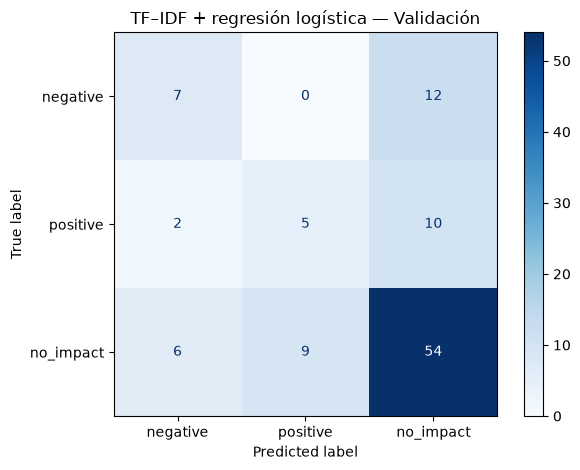

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    val_df["label"],
    pred_val,
    labels=list(CLASES),
    display_labels=list(CLASES.values()),
    cmap="Blues",
    values_format="d"
)

plt.title("TF–IDF + regresión logística — Validación")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    val_df["label"],
    pred_val,
    labels=list(CLASES)
)

display(pd.DataFrame(
    matriz,
    index=[f"Real: {nombre}" for nombre in CLASES.values()],
    columns=[f"Predicho: {nombre}" for nombre in CLASES.values()]
))

print(f"F1 macro del modelo clásico: {f1_clasico:.4f}")

,Predicho: negative,Predicho: positive,Predicho: no_impact
Real: negative,7,0,12
Real: positive,2,5,10
Real: no_impact,6,9,54


F1 macro del modelo clásico: 0.4931


In [10]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

modelo_sin_balanceo = clone(modelo_clasico).set_params(
    clasificador__class_weight=None
)

modelo_sin_balanceo.fit(
    train_df["verse_text"],
    train_df["label"]
)

pred_sin_balanceo = modelo_sin_balanceo.predict(
    val_df["verse_text"]
)

comparacion = pd.DataFrame([
    {
        "Modelo": "Referencia: clase mayoritaria",
        "Accuracy": accuracy_score(val_df["label"], predicciones),
        "F1 macro": f1_score(
            val_df["label"], predicciones,
            labels=list(CLASES),
            average="macro",
            zero_division=0
        )
    },
    {
        "Modelo": "TF–IDF + LogReg balanceada",
        "Accuracy": accuracy_score(val_df["label"], pred_val),
        "F1 macro": f1_clasico
    },
    {
        "Modelo": "TF–IDF + LogReg sin balanceo",
        "Accuracy": accuracy_score(
            val_df["label"], pred_sin_balanceo
        ),
        "F1 macro": f1_score(
            val_df["label"], pred_sin_balanceo,
            labels=list(CLASES),
            average="macro",
            zero_division=0
        )
    }
])

display(comparacion.round(4))

,Modelo,Accuracy,F1 macro
0,Referencia: clase mayoritaria,0.6571,0.2644
1,TF–IDF + LogReg balanceada,0.6286,0.4931
2,TF–IDF + LogReg sin balanceo,0.6667,0.3029


In [11]:
analisis_val = val_df[["id", "verse_text", "label"]].copy()

analisis_val["prediccion"] = pred_val
analisis_val["real"] = analisis_val["label"].map(CLASES)
analisis_val["predicho"] = analisis_val["prediccion"].map(CLASES)

errores = analisis_val.loc[
    analisis_val["label"] != analisis_val["prediccion"],
    ["verse_text", "real", "predicho"]
]

with pd.option_context("display.max_colwidth", None):
    display(errores.head(12))

,verse_text,real,predicho
1,"shall yet be glad for him, and he shall bless",positive,no_impact
2,"on its windy site uplifting gabled roof and palisade,",no_impact,negative
5,"when the brow is cold as the marble stone,",negative,no_impact
6,"taking and giving radiance, and the slopes",positive,negative
7,press hard the hostile towers!,negative,no_impact
11,and ever the rocks' disdain;,negative,no_impact
14,"a level space of nameless graves,--",no_impact,positive
21,with ten picked archers of my train;,no_impact,positive
22,"let fall on her a rose-leaf rain of dreams,",positive,no_impact
24,and politician at odd seasons.,no_impact,negative


En validación, la ponderación de clases incrementó el F1 macro de 0.3029 a 0.4931. La configuración sin ponderación obtuvo mayor accuracy, pero menor F1 macro, lo que muestra que ambas métricas reflejan aspectos distintos del desempeño.

In [12]:
vectorizador = modelo_clasico.named_steps["tfidf"]
vocabulario = vectorizador.vocabulary_
tokenizar = vectorizador.build_tokenizer()
preprocesar = vectorizador.build_preprocessor()

def cobertura_vocabulario(texto):
    palabras = tokenizar(preprocesar(texto))

    if not palabras:
        return 0.0

    conocidas = sum(palabra in vocabulario for palabra in palabras)
    return conocidas / len(palabras)

analisis_val["cobertura_vocabulario"] = (
    analisis_val["verse_text"].apply(cobertura_vocabulario)
)

analisis_val["acierto"] = (
    analisis_val["label"] == analisis_val["prediccion"]
)

print("Cobertura media de palabras por verso:")
display(
    analisis_val.groupby("acierto")["cobertura_vocabulario"]
    .agg(["mean", "count"])
    .rename(index={False: "Errores", True: "Aciertos"})
    .round(4)
)

with pd.option_context("display.max_colwidth", None):
    display(
        analisis_val.loc[
            ~analisis_val["acierto"],
            ["verse_text", "real", "predicho", "cobertura_vocabulario"]
        ].head(12)
    )

Cobertura media de palabras por verso:


,mean,count
acierto,,
Errores,0.7168,39
Aciertos,0.7328,66


,verse_text,real,predicho,cobertura_vocabulario
1,"shall yet be glad for him, and he shall bless",positive,no_impact,0.900000
2,"on its windy site uplifting gabled roof and palisade,",no_impact,negative,0.444444
5,"when the brow is cold as the marble stone,",negative,no_impact,1.000000
6,"taking and giving radiance, and the slopes",positive,negative,0.571429
7,press hard the hostile towers!,negative,no_impact,0.200000
11,and ever the rocks' disdain;,negative,no_impact,0.800000
14,"a level space of nameless graves,--",no_impact,positive,0.400000
21,with ten picked archers of my train;,no_impact,positive,0.571429
22,"let fall on her a rose-leaf rain of dreams,",positive,no_impact,0.777778
24,and politician at odd seasons.,no_impact,negative,0.400000


In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

parametros = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clasificador__C": [0.1, 1.0, 10.0]
}

busqueda = GridSearchCV(
    estimator=modelo_clasico,
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

busqueda.fit(
    train_df["verse_text"],
    train_df["label"]
)

print("Mejores parámetros:", busqueda.best_params_)
print(f"F1 macro medio en CV: {busqueda.best_score_:.4f}")

resultados_cv = pd.DataFrame(busqueda.cv_results_)

display(
    resultados_cv[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
)

Mejores parámetros: {'clasificador__C': 10.0, 'tfidf__ngram_range': (1, 1)}
F1 macro medio en CV: 0.4924


,params,mean_test_score,std_test_score,rank_test_score
4,"{'clasificador__C': 10.0, 'tfidf__ngram_range'...",0.492394,0.035967,1
2,"{'clasificador__C': 1.0, 'tfidf__ngram_range':...",0.490268,0.035092,2
1,"{'clasificador__C': 0.1, 'tfidf__ngram_range':...",0.487016,0.052434,3
3,"{'clasificador__C': 1.0, 'tfidf__ngram_range':...",0.486003,0.039174,4
0,"{'clasificador__C': 0.1, 'tfidf__ngram_range':...",0.485875,0.047943,5
5,"{'clasificador__C': 10.0, 'tfidf__ngram_range'...",0.481018,0.035110,6


In [14]:
modelo_clasico_ajustado = busqueda.best_estimator_

pred_val_ajustado = modelo_clasico_ajustado.predict(
    val_df["verse_text"]
)

f1_ajustado = f1_score(
    val_df["label"],
    pred_val_ajustado,
    labels=list(CLASES),
    average="macro",
    zero_division=0
)

print(f"F1 validación inicial:  {f1_clasico:.4f}")
print(f"F1 validación ajustado: {f1_ajustado:.4f}")

F1 validación inicial:  0.4931
F1 validación ajustado: 0.5509


Configuración seleccionada:
{'clasificador__C': 10.0, 'tfidf__ngram_range': (1, 1)}

Reporte en validación:
              precision    recall  f1-score   support

    negative     0.5385    0.3684    0.4375        19
    positive     0.5455    0.3529    0.4286        17
   no_impact     0.7284    0.8551    0.7867        69

    accuracy                         0.6857       105
   macro avg     0.6041    0.5255    0.5509       105
weighted avg     0.6644    0.6857    0.6655       105



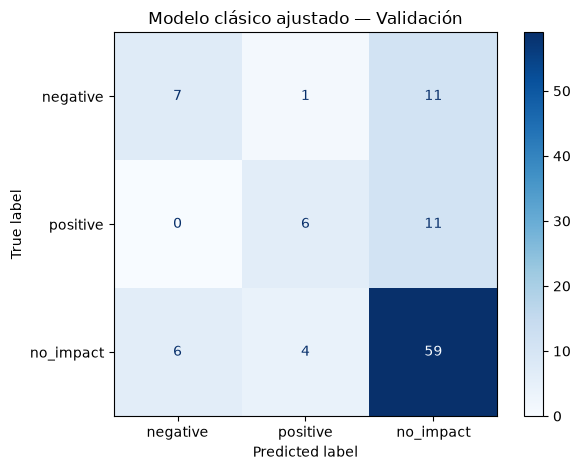

In [15]:
print("Configuración seleccionada:")
print(busqueda.best_params_)

print("\nReporte en validación:")
print(classification_report(
    val_df["label"],
    pred_val_ajustado,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    val_df["label"],
    pred_val_ajustado,
    labels=list(CLASES),
    display_labels=list(CLASES.values()),
    cmap="Blues",
    values_format="d"
)

plt.title("Modelo clásico ajustado — Validación")
plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path
import json
import platform
import joblib
import sklearn

salida = Path("artifacts/modelo_clasico")
salida.mkdir(parents=True, exist_ok=True)

# Incluye el vectorizador y el clasificador ya entrenados.
joblib.dump(
    modelo_clasico_ajustado,
    salida / "pipeline.joblib"
)

reporte = classification_report(
    val_df["label"],
    pred_val_ajustado,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    output_dict=True,
    zero_division=0
)

registro = {
    "modelo": "TF-IDF + LogisticRegression",
    "dataset": "google-research-datasets/poem_sentiment",
    "clases": CLASES,
    "clase_excluida": "mixed",
    "parametros_seleccionados": busqueda.best_params_,
    "class_weight": "balanced",
    "f1_macro_cv": float(busqueda.best_score_),
    "f1_macro_validacion": float(f1_ajustado),
    "reporte_validacion": reporte,
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "prueba_evaluada": False
}

with open(salida / "resultados.json", "w", encoding="utf-8") as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones_guardadas = val_df[
    ["id", "verse_text", "label"]
].copy()

predicciones_guardadas["prediccion"] = pred_val_ajustado
predicciones_guardadas.to_csv(
    salida / "predicciones_validacion.csv",
    index=False
)

print("Archivos guardados en:", salida.resolve())
print("Parámetros:", busqueda.best_params_)

Archivos guardados en: /Users/luisvazquez/Desktop/LAVP/Diplomado IA - CIC/PROYECTO_FINAL/Análisis de sentimientos en versos/poem-sentiment-v2/artifacts/modelo_clasico
Parámetros: {'clasificador__C': 10.0, 'tfidf__ngram_range': (1, 1)}


In [17]:
from pathlib import Path
import json
import joblib
import pandas as pd
from datasets import load_dataset
from sklearn.metrics import classification_report, f1_score

CLASES = {
    0: "negative",
    1: "positive",
    2: "no_impact"
}

carpeta = Path("artifacts/modelo_clasico")
modelo = joblib.load(carpeta / "pipeline.joblib")

dataset = load_dataset(
    "google-research-datasets/poem_sentiment"
)

test_df = dataset["test"].to_pandas().loc[
    lambda df: df["label"].isin(CLASES)
].copy()

pred_test_clasico = modelo.predict(test_df["verse_text"])

f1_test_clasico = f1_score(
    test_df["label"],
    pred_test_clasico,
    labels=list(CLASES),
    average="macro",
    zero_division=0
)

reporte = classification_report(
    test_df["label"],
    pred_test_clasico,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    output_dict=True,
    zero_division=0
)

print(f"F1 macro de prueba: {f1_test_clasico:.4f}\n")

print(classification_report(
    test_df["label"],
    pred_test_clasico,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

# Guardar la evaluación.
ruta_registro = carpeta / "resultados.json"

with open(ruta_registro, encoding="utf-8") as archivo:
    registro = json.load(archivo)

registro.update({
    "prueba_evaluada": True,
    "f1_macro_prueba": float(f1_test_clasico),
    "reporte_prueba": reporte
})

with open(ruta_registro, "w", encoding="utf-8") as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones = test_df[["id", "verse_text", "label"]].copy()
predicciones["prediccion"] = pred_test_clasico
predicciones.to_csv(carpeta / "predicciones_test.csv", index=False)

F1 macro de prueba: 0.4400

              precision    recall  f1-score   support

    negative     0.3125    0.2632    0.2857        19
    positive     0.4286    0.1875    0.2609        16
   no_impact     0.7160    0.8406    0.7733        69

    accuracy                         0.6346       104
   macro avg     0.4857    0.4304    0.4400       104
weighted avg     0.5981    0.6346    0.6054       104

